In [62]:
import pandas as pd

In [63]:
path = "./runs.csv"

In [64]:
df = pd.read_csv(path)

In [65]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 22 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   run                                                252 non-null    str    
 1   experiment                                         252 non-null    str    
 2   date                                               252 non-null    str    
 3   duration                                           252 non-null    str    
 4   training_time_seconds                              252 non-null    float64
 5   meta.dataset                                       252 non-null    str    
 6   meta.model                                         252 non-null    str    
 7   n_params                                           252 non-null    int64  
 8   dataset.use_time_features                          252 non-null    bool   
 9   decoder_outputs_scale

In [66]:
unique_models = df["meta.model"].value_counts()
for model in unique_models.index:
    print(model.replace("\"", ""))

HN-only-1st-BNSATT-NoPE-MGAT-LSTM
Shared-only-1st-BNSATT-NoPE-MGAT-LSTM
HN-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM
Shared-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM
HN-only-1st-BNSATT-NoPE-MGCN-LSTM
Shared-only-1st-BNSATT-NoPE-MGCN-LSTM
HN-only-1st-BNSATT-NoPE-GAT-LSTM
Shared-only-1st-BNSATT-NoPE-GAT-LSTM
HN-only-1st-BNSATT-NoPE-GCNSKIPCONN-LSTM
Shared-only-1st-BNSATT-NoPE-GCNSKIPCONN-LSTM
HN-only-1st-BNSATT-NoPE-GCN-LSTM
Shared-only-1st-BNSATT-NoPE-GCN-LSTM
MGAT-LSTM
MGCNSKIPCONN-LSTM
MGCN-LSTM
GAT-LSTM
GCNSKIPCONN-LSTM
GCN-LSTM
HSAR-NormFF-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-SH
HSAR-NormFF-Shared-only-1st-BNSATT-NoPE-MGAT-LSTM-SH
HSAR-NormFF-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-RH
HSAR-NormFF-Shared-only-1st-BNSATT-NoPE-MGAT-LSTM-RH
HSAR-NormFF-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-CH
HSAR-NormFF-Shared-only-1st-BNSATT-NoPE-MGAT-LSTM-CH
HSAR-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-SH
HSAR-Shared-only-1st-BNSATT-NoPE-MGAT-LSTM-SH
HSAR-HN-only-1st-BNSATT-NoPE-MGAT-LSTM-RH
HSAR-Shared-only-1st-BNSATT-NoPE-

In [67]:
df.columns

Index(['run', 'experiment', 'date', 'duration', 'training_time_seconds',
       'meta.dataset', 'meta.model', 'n_params', 'dataset.use_time_features',
       'decoder_outputs_scaled_mae subset="validation" ',
       'decoder_outputs_scaled_mae subset="test" ',
       'decoder_outputs_scaled_smape subset="validation" ',
       'decoder_outputs_scaled_smape subset="test" ',
       'decoder_outputs_scaled_rmse subset="validation" ',
       'decoder_outputs_scaled_rmse subset="test" ',
       'decoder_outputs_raw_mae subset="validation" ',
       'decoder_outputs_raw_mae subset="test" ',
       'decoder_outputs_raw_smape subset="validation" ',
       'decoder_outputs_raw_smape subset="test" ',
       'decoder_outputs_raw_rmse subset="validation" ',
       'decoder_outputs_raw_rmse subset="test" ',
       'model.postprocessing_layer'],
      dtype='str')

In [68]:
import re


regex = r"(?P<data_distribution>HSAR-)?(NormFF-)?((?P<attention_type>(?P<proj_type>HN|Shared)-(?P<att_state>only-1st|only-2nd|only-3rd|all)-(?P<att_fold>BN)SATT-(?P<pe>RoPE|NoPE))-)?(?P<cell_type>(?P<has_memory>M)?(?P<gnn_type>(GAT|GCN|GCNSKIPCONN))-LSTM)(?P<postprocessing_type>-(RH|CH|SH))?"

for row in df.iterrows():
    model_name = row[1]["meta.model"].replace("\"", "")
    result = re.match(regex, model_name)
    if result is not None:
        df.loc[row[0], "attention_type"] = result.group("attention_type")
        df.loc[row[0], "proj_type"] = result.group("proj_type")
        df.loc[row[0], "att_state"] = result.group("att_state")
        df.loc[row[0], "att_fold"] = result.group("att_fold")
        df.loc[row[0], "pe"] = result.group("pe")
        cell_type = result.group("cell_type")
        df.loc[row[0], "cell_type"] = cell_type
        df.loc[row[0], "gnn_type"] = result.group("gnn_type")
        df.loc[row[0], "postprocessing_type"] = result.group("postprocessing_type")

        # check if result has the group "data_distribution"
        if result.group("data_distribution") is not None:
            df.loc[row[0], "data_distribution"] = "different"
        else:
            df.loc[row[0], "data_distribution"] = "same"

        if any(cell in cell_type for cell in ["GAT-LSTM", "GCN-LSTM", "GCNSKIPCONN-LSTM"]):
            if result.group("has_memory") is not None:
                df.loc[row[0], "has_memory"] = True
            else:
                df.loc[row[0], "has_memory"] = False
    else:
        print(f"Model: {model_name} does not match the regex.")

In [69]:
df

,run,experiment,date,duration,training_time_seconds,meta.dataset,meta.model,n_params,dataset.use_time_features,"decoder_outputs_scaled_mae subset=""validation""",...,attention_type,proj_type,att_state,att_fold,pe,cell_type,gnn_type,postprocessing_type,data_distribution,has_memory
0,Run: 15875a68e74d4ea58b6b4ac4,seasonal-validation-pv-italy-HN-only-1st-BNSAT...,"17:30:50 · 20 Oct, 26",1min 1sec,52.786209,"""pv-italy""","""HN-only-1st-BNSATT-NoPE-MGAT-LSTM""",210852,True,0.059344,...,HN-only-1st-BNSATT-NoPE,HN,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
1,Run: fdda78c543a044869cdd9e64,seasonal-validation-pv-italy-Shared-only-1st-B...,"17:29:52 · 20 Oct, 26",2min 619ms,48.473601,"""pv-italy""","""Shared-only-1st-BNSATT-NoPE-MGAT-LSTM""",13788,True,0.061481,...,Shared-only-1st-BNSATT-NoPE,Shared,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
2,Run: 8369238765b04bd3add92837,seasonal-validation-pv-italy-HN-only-1st-BNSAT...,"17:29:04 · 20 Oct, 26",46sec 948ms,37.989356,"""pv-italy""","""HN-only-1st-BNSATT-NoPE-MGAT-LSTM""",90960,False,0.061493,...,HN-only-1st-BNSATT-NoPE,HN,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
3,Run: 08635c5882e64a358ad0df96,seasonal-validation-pv-italy-Shared-only-1st-B...,"17:28:17 · 20 Oct, 26",46sec 689ms,37.293901,"""pv-italy""","""Shared-only-1st-BNSATT-NoPE-MGAT-LSTM""",5952,False,0.062237,...,Shared-only-1st-BNSATT-NoPE,Shared,only-1st,BN,NoPE,MGAT-LSTM,GAT,None,same,True
4,Run: 864d39d14f0c48268d87b420,seasonal-validation-pv-italy-HN-only-1st-BNSAT...,"17:27:30 · 20 Oct, 26",46sec 877ms,36.461873,"""pv-italy""","""HN-only-1st-BNSATT-NoPE-MGCNSKIPCONN-LSTM""",206344,True,0.057940,...,HN-only-1st-BNSATT-NoPE,HN,only-1st,BN,NoPE,MGCNSKIPCONN-LSTM,GCNSKIPCONN,None,same,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,Run: 9d35030e6fdb42fe9f27e9e5,seasonal-validation-pv-italy-HSAR-GCN-LSTM-RH,"11:57:15 · 20 Oct, 26",19sec 617ms,11.632163,"""pv-italy""","""HSAR-GCN-LSTM-RH""",7378,True,0.070195,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-RH,different,False
248,Run: 78805c6b33064e2086c8834d,seasonal-validation-pv-italy-HSAR-GCN-LSTM-CH,"11:56:56 · 20 Oct, 26",39sec 285ms,11.450417,"""pv-italy""","""HSAR-GCN-LSTM-CH""",2561,True,0.065759,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-CH,different,False
249,Run: 9339205d66054befae3e3697,seasonal-validation-pv-italy-HSAR-GCN-LSTM-SH,"11:56:39 · 20 Oct, 26",16sec 529ms,8.611855,"""pv-italy""","""HSAR-GCN-LSTM-SH""",1068,False,0.066681,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-SH,different,False
250,Run: b17a1c33077c474881edaceb,seasonal-validation-pv-italy-HSAR-GCN-LSTM-RH,"11:56:22 · 20 Oct, 26",33sec 632ms,9.328978,"""pv-italy""","""HSAR-GCN-LSTM-RH""",4252,False,0.074897,...,NaN,NaN,NaN,NaN,NaN,GCN-LSTM,GCN,-RH,different,False


In [70]:
import seaborn as sns
import matplotlib.pyplot as plt

In [121]:
col = "data_distribution" # ["proj_type", 'dataset.use_time_features', "data_distribution", "postprocessing_type"]
# replace None with "None"
df[col] = df[col].fillna("None")
df[col].value_counts()

data_distribution
different    216
same          36
Name: count, dtype: int64

<Axes: xlabel='data_distribution', ylabel='decoder_outputs_scaled_rmse subset="test" '>

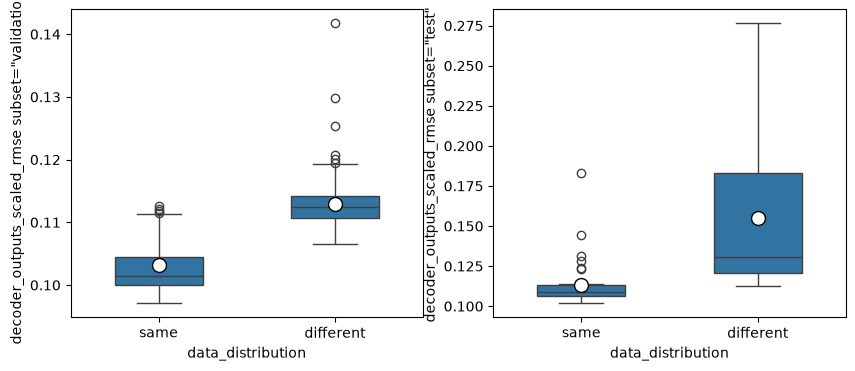

In [122]:
# show boxplots of the decoder_outputs_scaled_mae for each attention_type in both validation and test, using only the test subset
# show also the mean and median line in the same plot, using a different color for each
# the left plot is for valdiation while the right plot is for test

metric = "rmse"

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(
    data=df, 
    x=col, 
    y=f'decoder_outputs_scaled_{metric} subset="validation" ',
    showmeans=True,
    width=0.5,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"10"},
    ax=axes[0],
)
sns.boxplot(
    data=df, 
    x=col, 
    y=f'decoder_outputs_scaled_{metric} subset="test" ',
    showmeans=True,
    width=0.5,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"10"},
    ax=axes[1],
)


<Axes: xlabel='data_distribution', ylabel='n_params'>

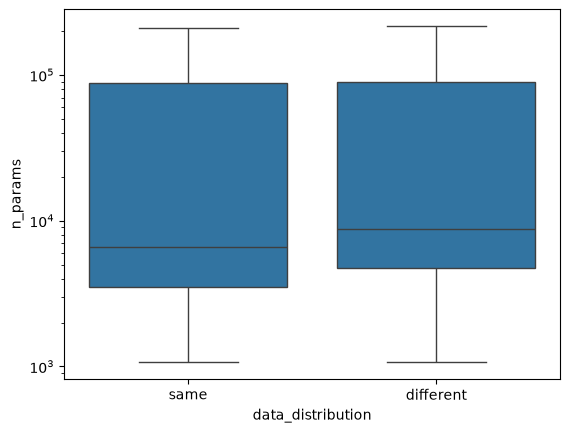

In [123]:
sns.boxplot(
    data=df, 
    x=col, 
    y='n_params',
    # use log scale for y axis
    log_scale=True
)